In [10]:
import os
import re
import kagglehub
import pandas as pd
from sklearn.model_selection import train_test_split

path = kagglehub.dataset_download("snap/amazon-fine-food-reviews")
df_full = pd.read_csv(os.path.join(path, "Reviews.csv"))
df = df_full.sample(n=50000, random_state=42)

df = df.dropna(subset=["Text", "Score"]).copy()
df = df.drop_duplicates(subset=["Text"]).copy()

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"[^a-z0-9\s']", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

df["Clean_Text"] = df["Text"].apply(clean_text)
df = df[df["Clean_Text"] != ""].copy()
df["Sentiment"] = (df["Score"] >= 4).astype(int)

train_df, test_df = train_test_split(
    df,
    test_size=0.20,
    random_state=42,
    stratify=df["Sentiment"]
)

sub_train_df, val_df = train_test_split(
    train_df,
    test_size=0.15,
    random_state=42,
    stratify=train_df["Sentiment"]
)

train_df.to_csv("alpha_train.csv", index=False)
test_df.to_csv("alpha_test.csv", index=False)

print("Saved alpha_train.csv:", len(train_df), "| alpha_test.csv:", len(test_df))

Saved alpha_train.csv: 37054 | alpha_test.csv: 9264


In [ ]:
from gensim.models import Word2Vec

# Tokenize training reviews into lists of words
tokenized_reviews = [
    text.split()
    for text in train_df["Clean_Text"].fillna("").astype(str)
]

# Train Word2Vec on training reviews
word2vec = Word2Vec(
    sentences=tokenized_reviews,
    vector_size=100,
    window=5,
    min_count=2,
    workers=2,
    seed=42,
    epochs=5
)

print("Embedding dimensions:", word2vec.vector_size)
print("Vocabulary size:", len(word2vec.wv))

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Embedding dimensions: 100
Vocabulary size: 22085


Epoch [1/5] - Train Loss: 0.3669 - Val Loss: 0.2904
Epoch [2/5] - Train Loss: 0.2877 - Val Loss: 0.2450
Epoch [3/5] - Train Loss: 0.2455 - Val Loss: 0.2291
Epoch [4/5] - Train Loss: 0.2154 - Val Loss: 0.2277
Epoch [5/5] - Train Loss: 0.1838 - Val Loss: 0.2295


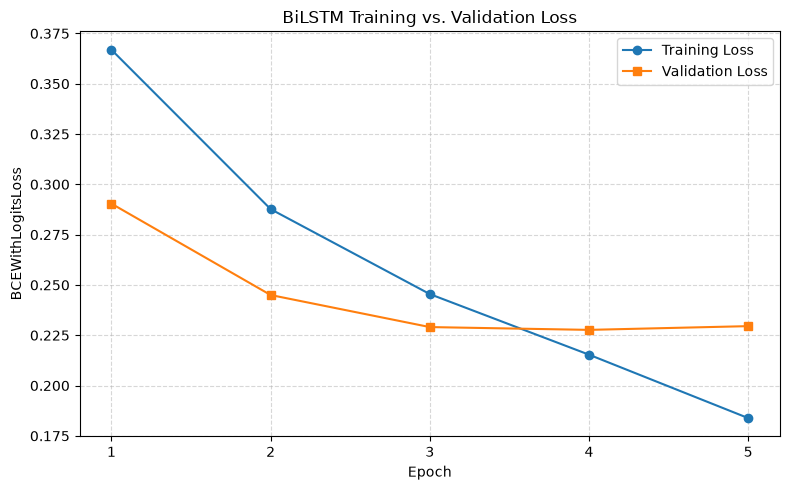


Test Accuracy: 0.8981001727115717

Classification Report:
               precision    recall  f1-score   support

           0       0.77      0.75      0.76      2019
           1       0.93      0.94      0.94      7245

    accuracy                           0.90      9264
   macro avg       0.85      0.85      0.85      9264
weighted avg       0.90      0.90      0.90      9264


Confusion Matrix:
 [[1522  497]
 [ 447 6798]]


In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import numpy as np
import matplotlib.pyplot as plt
import time
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

np.random.seed(42)
torch.manual_seed(42)

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)

word2idx = {"<PAD>": 0, "<UNK>": 1}
for word in word2vec.wv.index_to_key:
    word2idx[word] = len(word2idx)

embed_dim = word2vec.vector_size
embedding_matrix = np.zeros((len(word2idx), embed_dim), dtype=np.float32)

rng = np.random.default_rng(42)
embedding_matrix[1] = rng.normal(scale=0.25, size=(embed_dim,)).astype(np.float32)

for word, idx in word2idx.items():
    if word in word2vec.wv:
        embedding_matrix[idx] = word2vec.wv[word]

def create_review_sequences(texts, word2idx, seq_length=150):
    seqs = np.zeros((len(texts), seq_length), dtype=np.int64)
    for i, text in enumerate(texts):
        tokens = str(text).split()[:seq_length]
        for j, token in enumerate(tokens):
            seqs[i, j] = word2idx.get(token, word2idx["<UNK>"])
    return seqs

seq_length = 150
sub_trainX_np = create_review_sequences(sub_train_df["Clean_Text"].fillna("").astype(str), word2idx, seq_length)
valX_np = create_review_sequences(val_df["Clean_Text"].fillna("").astype(str), word2idx, seq_length)
testX_np = create_review_sequences(test_df["Clean_Text"].fillna("").astype(str), word2idx, seq_length)

sub_trainY_np = sub_train_df["Sentiment"].astype(np.float32).to_numpy()
valY_np = val_df["Sentiment"].astype(np.float32).to_numpy()
testY_np = test_df["Sentiment"].astype(np.float32).to_numpy()

class ReviewDataset(Dataset):
    def __init__(self, x, y):
        self.x = torch.tensor(x, dtype=torch.long)
        self.y = torch.tensor(y[:, None], dtype=torch.float32)  # shape: (N, 1)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.x[idx], self.y[idx]

batch_size = 64
sub_train_loader = DataLoader(ReviewDataset(sub_trainX_np, sub_trainY_np), batch_size=batch_size, shuffle=True)
val_loader = DataLoader(ReviewDataset(valX_np, valY_np), batch_size=batch_size, shuffle=False)
test_loader = DataLoader(ReviewDataset(testX_np, testY_np), batch_size=batch_size, shuffle=False)

class LSTMModel(nn.Module):
    def __init__(self, embedding_matrix, hidden_dim=128, layer_dim=2, output_dim=1, dropout=0.3, freeze_embeddings=False):
        super().__init__()
        _, input_dim = embedding_matrix.shape

        self.embedding = nn.Embedding.from_pretrained(
            torch.tensor(embedding_matrix, dtype=torch.float32),
            freeze=freeze_embeddings,
            padding_idx=0
        )
        self.emb_dropout = nn.Dropout(dropout)
        self.lstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=layer_dim,
            batch_first=True,
            bidirectional=True,
            dropout=dropout if layer_dim > 1 else 0.0
        )
        self.fc = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(hidden_dim * 4, output_dim)
        )

    def forward(self, x):
        emb = self.emb_dropout(self.embedding(x))          
        out, _ = self.lstm(emb)                            

        max_pool = torch.max(out, dim=1).values            
        mean_pool = torch.mean(out, dim=1)                 
        feat = torch.cat([max_pool, mean_pool], dim=1)    

        logits = self.fc(feat)                           
        return logits

model = LSTMModel(
    embedding_matrix=embedding_matrix,
    hidden_dim=128,
    layer_dim=2,
    output_dim=1,
    dropout=0.3,
    freeze_embeddings=False
).to(device)

criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-5)

num_epochs = 5
train_losses = []
val_losses = []

start_time = time.perf_counter()

for epoch in range(num_epochs):
    # --- Train ---
    model.train()
    running_train_loss = 0.0

    for batch_x, batch_y in sub_train_loader:
        batch_x, batch_y = batch_x.to(device), batch_y.to(device)
        optimizer.zero_grad()

        outputs = model(batch_x)
        loss = criterion(outputs, batch_y)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        running_train_loss += loss.item() * batch_x.size(0)

    epoch_train_loss = running_train_loss / len(sub_train_loader.dataset)
    train_losses.append(epoch_train_loss)

    model.eval()
    running_val_loss = 0.0

    with torch.no_grad():
        for batch_x, batch_y in val_loader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
            outputs = model(batch_x)
            loss = criterion(outputs, batch_y)
            running_val_loss += loss.item() * batch_x.size(0)

    epoch_val_loss = running_val_loss / len(val_loader.dataset)
    val_losses.append(epoch_val_loss)

    print(f"Epoch [{epoch+1}/{num_epochs}] - Train Loss: {epoch_train_loss:.4f} - Val Loss: {epoch_val_loss:.4f}")

train_elapsed_sec = time.perf_counter() - start_time
print(f"Model training time: {train_elapsed_sec:.2f}s ({train_elapsed_sec / 60:.2f} min)")

epochs_range = range(1, num_epochs + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs_range, train_losses, marker="o", label="Training Loss")
plt.plot(epochs_range, val_losses, marker="s", label="Validation Loss")
plt.title("BiLSTM Training vs. Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("BCEWithLogitsLoss")
plt.xticks(epochs_range)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("lstm_loss_curves.png", dpi=300)
plt.show()


model.eval()
all_preds = []

with torch.no_grad():
    for batch_x, _ in test_loader:
        batch_x = batch_x.to(device)
        logits = model(batch_x)
        probs = torch.sigmoid(logits).squeeze(1).cpu().numpy()
        all_preds.extend((probs >= 0.5).astype(int))

y_true = testY_np.astype(int)
print("\nTest Accuracy:", accuracy_score(y_true, all_preds))
print("\nClassification Report:\n", classification_report(y_true, all_preds))
print("\nConfusion Matrix:\n", confusion_matrix(y_true, all_preds))